# Transaction Value Prediction

This notebook tests whether basic transaction details can help estimate recorded real estate sale values in Saudi Arabia. It uses transactions from Q1 2024 for training and Q2 2024 for evaluation.

The target is **total transaction value in SAR**, not the price of an individual home. Some records include more than one property.

## Libraries

Pandas and NumPy are used for data preparation, scikit-learn for modeling and evaluation, and Matplotlib for the error comparison.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, median_absolute_error, r2_score

## Dataset

The input is `real_estate_clean.csv`, which contains the Q1 and Q2 sales records used in the Power BI report.

In [2]:
df = pd.read_csv("../data/real_estate_clean.csv")
print("Rows:", len(df))
print("Q1 and Q2:")
print(df["quarter"].value_counts())
df.head()

Rows: 107370
Q1 and Q2:
quarter
Q1    59099
Q2    48271
Name: count, dtype: int64


,المنطقة,المدينة,المدينة / الحي,الرقم المرجعي للصفقة,تاريخ الصفقة ميلادي,تاريخ الصفقة هجري,تصنيف العقار,عدد العقارات,السعر,المساحة,quarter
0,مكة المكرمه,الطائف,الطائف/ الجودية,21996239,1/1/2024,1445/06/19,سكني,1,160000,555.0,Q1
1,الرياض,الرياض,الرياض/السليمانية,21997463,1/1/2024,1445/06/19,سكني,1,3575000,330.0,Q1
2,الرياض,الرياض,الرياض/السليمانية,21997409,1/1/2024,1445/06/19,سكني,1,3575000,330.0,Q1
3,الرياض,الدلم,الدلم/أخرى,21997190,1/1/2024,1445/06/19,سكني,1,530000,5291.0,Q1
4,نجران,شروره,شروره/ الوديعة,22000244,1/1/2024,1445/06/19,تجاري,1,5000,625.0,Q1


## Features and target

The model uses region, city, property classification, area, and number of properties to estimate transaction value (`السعر`).

Transaction IDs are excluded because they do not describe a property's value. Price per square metre is also excluded because it is calculated from the target and would leak the answer.

In [3]:
features = ["المنطقة", "المدينة", "تصنيف العقار", "المساحة", "عدد العقارات"]
target = "السعر"

print(df[features + [target]].head())

       المنطقة المدينة تصنيف العقار  المساحة  عدد العقارات    السعر
0  مكة المكرمه  الطائف         سكني    555.0             1   160000
1       الرياض  الرياض         سكني    330.0             1  3575000
2       الرياض  الرياض         سكني    330.0             1  3575000
3       الرياض   الدلم         سكني   5291.0             1   530000
4        نجران   شروره        تجاري    625.0             1     5000


## Train and test data

Q1 2024 is the training set and Q2 2024 is the test set. Keeping the later quarter separate provides a more realistic check than testing on records seen during training.

In [4]:
train = df[df["quarter"] == "Q1"].copy()
test = df[df["quarter"] == "Q2"].copy()

X_train = train[features]
X_test = test[features]
y_train = train[target]
y_test = test[target]

print("Training rows:", len(train))
print("Test rows:", len(test))

Training rows: 59099
Test rows: 48271


## Categorical variables

Region, city, and property classification are converted into indicator columns using `get_dummies()`. The Q2 columns are aligned with the Q1 columns so both datasets have the same model inputs.

In [5]:
X_train = pd.get_dummies(X_train)
X_test = pd.get_dummies(X_test)
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

print("Number of model inputs:", X_train.shape[1])

Number of model inputs: 169


## Baseline

The baseline predicts the Q1 median sale value for every Q2 record. Its error provides a simple reference for the regression model.

In [6]:
baseline_value = y_train.median()
baseline_predictions = np.full(len(y_test), baseline_value)

baseline_mae = mean_absolute_error(y_test, baseline_predictions)
print(f"Baseline prediction: SAR {baseline_value:,.0f}")
print(f"Baseline MAE: SAR {baseline_mae:,.0f}")

Baseline prediction: SAR 453,750
Baseline MAE: SAR 971,593


## Random Forest

A Random Forest Regressor is fitted with 40 trees and a limit on tree depth. The target is log-transformed during training to reduce the effect of very large transactions; predictions are converted back to SAR for evaluation.

In [7]:
model = RandomForestRegressor(
    n_estimators=40,
    max_depth=14,
    min_samples_leaf=10,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, np.log1p(y_train))
predictions = np.expm1(model.predict(X_test))
print("Model trained")

Model trained


## Model performance

Performance is measured with mean absolute error (MAE), median absolute error, and R². MAE and median error are reported in SAR, making them easier to compare with actual transaction values.

In [8]:
model_mae = mean_absolute_error(y_test, predictions)
model_median_error = median_absolute_error(y_test, predictions)
model_r2 = r2_score(y_test, predictions)

comparison = pd.DataFrame({
    "Method": ["Median baseline", "Random Forest"],
    "MAE (SAR)": [baseline_mae, model_mae],
    "Median error (SAR)": [
        median_absolute_error(y_test, baseline_predictions),
        model_median_error
    ]
})
print(comparison.round(0).to_string(index=False))
print(f"Random Forest R²: {model_r2:.2f}")
print(f"MAE improvement: {(baseline_mae - model_mae) / baseline_mae * 100:.1f}%")

         Method  MAE (SAR)  Median error (SAR)
Median baseline   971593.0            313750.0
  Random Forest   757544.0            170733.0
Random Forest R²: 0.18
MAE improvement: 22.0%


## Baseline vs. model

The chart compares the average absolute prediction error of the median baseline and Random Forest on Q2 transactions. Lower MAE indicates better performance.

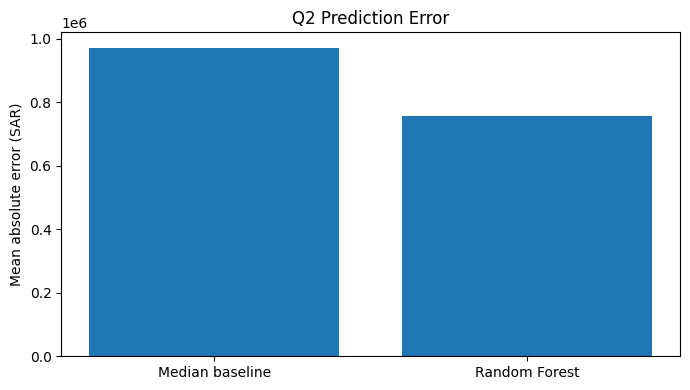

In [9]:
plt.figure(figsize=(7, 4))
plt.bar(comparison["Method"], comparison["MAE (SAR)"])
plt.title("Q2 Prediction Error")
plt.ylabel("Mean absolute error (SAR)")
plt.tight_layout()
plt.show()

## Actual and predicted values

A small sample of Q2 transactions is shown with the model prediction and absolute error, to put the overall metrics in context.

In [10]:
results = test[["المنطقة", "المدينة", "تصنيف العقار", "المساحة", "السعر"]].copy()
results["Predicted"] = predictions.round(0)
results["Absolute error"] = (results["السعر"] - results["Predicted"]).abs()
results.sample(8, random_state=42)

,المنطقة,المدينة,تصنيف العقار,المساحة,السعر,Predicted,Absolute error
69573,الرياض,الرياض,سكني,375.00,725000,643908.0,81092.0
89033,الحدود الشمالية,عرعر,سكني,630.00,61000,24452.0,36548.0
85851,مكة المكرمه,رنيه,سكني,890.76,5000,10685.0,5685.0
78699,الرياض,الرياض,سكني,300.00,562500,449442.0,113058.0
77464,حائل,حائل,تجاري,594.00,891000,133114.0,757886.0
93408,المدينة المنوره,المدينة المنورة,سكني,612.43,1377967,498428.0,879539.0
80578,حائل,حائل,تجاري,1010.00,850000,133114.0,716886.0
83996,مكة المكرمه,جده,تجاري,270.00,611204,893507.0,282303.0


## Error by property classification

Prediction errors are also grouped by residential, commercial, and agricultural records. The model has the highest mean absolute error on commercial transactions, so its performance is not consistent across categories.

In [11]:
error_by_type = results.groupby("تصنيف العقار")["Absolute error"].agg(
    ["count", "mean", "median"]
)
error_by_type.round(0)

,count,mean,median
تصنيف العقار,,,
تجاري,4605,3017417.0,411638.0
زراعي,1632,1117169.0,415497.0
سكني,42034,496003.0,153119.0


## Largest errors

The largest absolute errors mostly involve unusually high transaction values. These records have a strong effect on overall MAE.

In [12]:
results.nlargest(5, "Absolute error")[[
    "المنطقة", "المدينة", "تصنيف العقار", "السعر", "Predicted", "Absolute error"
]]

,المنطقة,المدينة,تصنيف العقار,السعر,Predicted,Absolute error
92028,الرياض,الرياض,تجاري,1628410300,84137224.0,1.544273e+09
99626,مكة المكرمه,جده,سكني,600000000,24370949.0,5.756291e+08
86575,الرياض,الرياض,تجاري,648500000,84137224.0,5.643628e+08
99471,الرياض,الرياض,سكني,498393181,79607681.0,4.187855e+08
105900,الرياض,الرياض,تجاري,480000000,82818807.0,3.971812e+08


## Results

On Q2 2024 records, Random Forest achieved an **MAE of SAR 757,544**, compared with **SAR 971,593** for the median baseline (about **22% lower**). Its median absolute error was **SAR 170,733** and its **R² was 0.18**.
